# Ariketa 3.3: xG neurona bat zerotik ⚽ (EGITEKO)

Helburua ez da soilik kodea osatzea. Koadernoaren amaieran ulertu behar duzu:

> **nola bihurtzen diren input-ak probabilitate, nola neurtzen den errorea eta nola ikasten diren pisuak.**


## 📝 Nola egin

- 🟢 **EMANDA:** exekutatu eta ulertu.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** zati osoa idatzi.

Ariketaren muina **B atala** da: neurona logistikoa zerotik eraikitzea.


# A ATALA — Datuak eta preprocessing-a 🟢🟡

Lehenengo, entrenatuko dugun ereduarentzat datuak prestatu behar ditugu.

Ariketa honetan dataset-a **guk geuk simulatuko dugu**. Horrek abantaila didaktiko handia du:

> datuak sortzeko erabili dugun “arau sekretua” guk ezagutzen dugu, baina gero entrenatuko dugun neuronak **ez**.

A atalaren ibilbidea:

```text
jaurtiketa sintetikoak sortu
        ↓
datuak begiratu
        ↓
TRAIN / TEST banatu
        ↓
nuluak TRAIN-ekin konpondu
        ↓
X eta y prestatu
        ↓
eskalatu
        ↓
neurona entrenatzeko prest
```


## A.0 — Datuak sortu (EMANDA) 🟢


### A.0 ulertzeko ideia nagusia

Datuak sortzeko **eredu ezkutu** bat asmatuko dugu:

$$
z_{\mathrm{true}}
=
3.2
-0.17 \cdot \mathrm{distantzia}
-0.035 \cdot \mathrm{angelua}
-0.35 \cdot \mathrm{buruz}
$$

> **`z_true` ez da xG-a.**  
> Ezaugarriak pisuekin konbinatzen dituen **puntuazio ezkutua** da.

Koefizienteen esanahi intuitiboa:

- `3.2` → **bias/intercept**: abiapuntuko puntuazioa.
- `-0.17 · distantzia` → metro gehiago → `z` txikiago.
- `-0.035 · angelua` → zentrotik alboago → `z` txikiago.
- `-0.35 · buruz` → buruzkoa bada (`1`), `z`-ri `0.35` kentzen zaio.

Ondoren sigmoideak puntuazioa probabilitate bihurtzen du:

$$
p_{\mathrm{true}}
=
\sigma\!\left(z_{\mathrm{true}}\right)
=
\frac{1}{1+e^{-z_{\mathrm{true}}}}
$$

Beraz:

```text
jaurtiketaren ezaugarriak
        ↓
z_true = puntuazioa
        ↓
sigmoidea
        ↓
p_true = xG sintetikoa
        ↓
ausazko saiakera
        ↓
gola = 0 edo 1
```

`p_true = 0.80` bada, **ez** dugu esaten gola ziurra dela.  
Esan nahi du gure mundu sintetikoan jaurtiketa horrek gutxi gorabehera **%80ko gol-probabilitatea** duela.

### Ariketaren ideia pedagogikoa

> **Datuak sortzean guk ezagutzen dugu araua.**  
> **Eredua entrenatzean neuronak arau hori adibideetatik aurkitzen saiatzen da.**

Horregatik:

- `z_true`, `p_true` → dataset-a sortzeko guk dakigun *ground truth*.
- `w`, `b` → neuronak TRAIN datuetatik **ikasi behar dituen** parametroak.


### ⚠️ Ohar garrantzitsua: `buruz` ez erabiltzea ≠ `buruz = 0`

Dataset-a sortzean:

```text
buruz = 0  → oinez
buruz = 1  → buruz
```

Eta **bi motatako jaurtiketak** egongo dira dataset-ean.

Baina lehen neuronari honako bi input hauek bakarrik emango dizkiogu:

```text
distantzia
angelua
```

Horrek **EZ** du esan nahi jaurtiketa guztiak oinezkoak direnik.

Esan nahi du:

> **Neuronak ez du gorputz-atalaren informazioa ikusten.**

Adibidez:

```text
A → 10 m, 5°, oinez
B → 10 m, 5°, buruz
```

`buruz` ezaugarria kenduta, neuronak biak berdin ikusiko ditu:

```text
A → [10, 5]
B → [10, 5]
```

### Gogoratzeko

> **Ezaugarria kentzea ≠ ezaugarria 0 izatea.**  
> **Ezaugarria kentzea = ereduak informazio hori ez ikustea.**

Beraz lehen neuronak hau ikasiko du:

$$
\hat{z}
=
b+w_1\cdot\mathrm{distantzia}
+w_2\cdot\mathrm{angelua}
$$

Amaierako erronkan `buruz` hirugarren input gisa gehituko dugu.


In [1]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 0. AUSAZKOTASUNA KONTROLATU
# ---------------------------------------------------------

# Ausazko zenbakiak sortzeko sorgailua.
# 42 = seed-a: koadernoa berriro exekutatzean
# ausazko sekuentzia bera lortuko dugu.
# Horrela ikasle guztiek dataset bera izango dute.
rng = np.random.default_rng(42)

# Simulatuko ditugun jaurtiketa kopurua
n_jaurtiketa = 600


# ---------------------------------------------------------
# 1. DISTANTZIA
# ---------------------------------------------------------

# uniform(low, high, size):
# 4 eta 32 metro arteko 600 balio ausaz sortu.
# Uniform banaketan tarteko balio guztiek aukera bera dute.
# (Hau sinplifikazio didaktikoa da; benetako futbol-datuak
# ez dira derrigor distantzian uniformeki banatzen.)
dist = rng.uniform(
    low=4,
    high=32,
    size=n_jaurtiketa
)


# ---------------------------------------------------------
# 2. ZENTROTIK ANGELUA
# ---------------------------------------------------------

# 0°  = guztiz aurrez aurre
# 55° = oso albo batetik
#
# Berriro uniform banaketa erabiltzen dugu.
ang = rng.uniform(
    low=0,
    high=55,
    size=n_jaurtiketa
)


# ---------------------------------------------------------
# 3. GORPUTZ-ATALA
# ---------------------------------------------------------

# Jaurtiketa bakoitzean:
# 0 -> oinez
# 1 -> buruz
#
# binomial(n=1, p=0.20):
# saiakera bakoitzean 1 ateratzeko %20ko probabilitatea.
# Beraz, jaurtiketa bakoitzak %20ko aukera du buruzkoa izateko.
#
# Horrek EZ du bermatzen zehazki 120/600 buruzkoak izango direnik;
# batez beste %20 inguruan espero dugu.
buruz = rng.binomial(
    n=1,
    p=0.20,
    size=n_jaurtiketa
)


# ---------------------------------------------------------
# 4. "ARAU SEKRETUA": z_true
# ---------------------------------------------------------

# Jaurtiketa bakoitzari puntuazio ezkutua kalkulatzen diogu.
# z_true ORAINDIK ez da probabilitatea.
z_true = (
    3.2
    - 0.17 * dist
    - 0.035 * ang
    - 0.35 * buruz
)


# ---------------------------------------------------------
# 5. PUNTUAZIOA -> PROBABILITATEA
# ---------------------------------------------------------

# Sigmoideak z_true balio bakoitza 0 eta 1 arteko
# probabilitate bihurtzen du.
p_true = 1 / (1 + np.exp(-z_true))


# ---------------------------------------------------------
# 6. PROBABILITATEA -> GOLA / EZ GOLA
# ---------------------------------------------------------
# p_true-k jaurtiketa bakoitzaren gol-probabilitatea gordetzen du.
#
# Orain probabilitate hori benetako emaitza batean bihurtuko dugu:
#
#   1 -> gola
#   0 -> ez gola
#
# Adibidez, p_true = 0.80 bada:
#   %80ko aukera dago 1 ateratzeko
#   %20ko aukera dago 0 ateratzeko
#
# n=1 -> jaurtiketa bakoitzean emaitza bakarra sortzen dugu
# Labur: p_true probabilitatea da eta
# rng.binomial() probabilitate horren arabera 0 edo 1 sortzen du.
gola = rng.binomial(
    n=1,
    p=p_true
)

# ---------------------------------------------------------
# 7. DATAFRAME-A SORTU
# ---------------------------------------------------------

df = pd.DataFrame({
    'distantzia_m': dist.round(1),
    'zentrotik_angelua': ang.round(1),
    'gorputz_atala': np.where(buruz == 1, 'burua', 'oina'),
    'gola': gola
})


# ---------------------------------------------------------
# 8. BALIO FALTA BATZUK SARTU
# ---------------------------------------------------------

# 15 errenkada desberdin aukeratzen ditugu ausaz.
# replace=False -> indize bera ez da bi aldiz aukeratuko.
indize_nuluak = rng.choice(
    n_jaurtiketa,
    size=15,
    replace=False
)

# Aukeratutako 15 jaurtiketen angelua NaN bihurtu.
# Gero preprocessing-ean konpondu beharko dugu.
df.loc[indize_nuluak, 'zentrotik_angelua'] = np.nan


print('Sortuta:', df.shape)
print('Buruzko jaurtiketak:', buruz.sum(), '/', n_jaurtiketa)


Sortuta: (600, 4)
Buruzko jaurtiketak: 133 / 600


## A.1 — Begiratu datuak 🟢

Entrenatzen hasi aurretik dataset-a **ulertu** behar dugu.

Begiratuko dugu:

- zenbat errenkada eta zutabe dauden;
- zenbat jaurtiketa amaitu diren golean;
- balio faltarik dagoen;
- lehenengo errenkadak nolakoak diren.

### Zergatik ematen du `mean()`-ek gol-tasa?

`gola` zutabean:

```text
1 = gola
0 = ez gola
```

0 eta 1en batezbestekoa kalkulatzean, emaitza `1`-en proportzioa da.

Adibidez:

```text
[1, 0, 0, 1] → mean = 0.50 → %50 gol
```


In [2]:
# shape -> (errenkada kopurua, zutabe kopurua)
print('Forma:', df.shape)

# gola 0/1 denez, mean() = 1-en proportzioa = gol-tasa
print('Gol-tasa:', round(df['gola'].mean(), 3))

# Zutabe bakoitzean zenbat NaN dauden;
# >0 dutenak bakarrik erakusten ditugu.
print('Nuluak:')
print(df.isnull().sum()[lambda s: s > 0])

# Lehenengo 5 jaurtiketak ikusi
df.head()


Forma: (600, 4)
Gol-tasa: 0.365
Nuluak:
zentrotik_angelua    15
dtype: int64


,distantzia_m,zentrotik_angelua,gorputz_atala,gola
0,25.7,26.3,oina,0
1,16.3,41.9,oina,0
2,28.0,49.7,burua,0
3,23.5,39.6,oina,0
4,6.6,53.0,oina,0


## A.2 — Lehenengo TRAIN / TEST banaketa 🟢

**Preprocessing-a egin AURRETIK** banatuko ditugu datuak.

```text
dataset osoa
    ↓
TRAIN (%80)  → ikasteko
TEST  (%20)  → amaieran ebaluatzeko
```

### Bi `42` desberdin

Lehenago:

```python
np.random.default_rng(42)
```

erabili dugu **dataset sintetikoa sortzeko** ausazkotasuna kontrolatzeko.

Orain:

```python
random_state=42
```

erabiliko dugu **TRAIN / TEST banaketa** errepikagarria izateko.

Biak reproducibility-rako dira, baina **bi ausazko prozesu desberdin** kontrolatzen dituzte.

### Zer egiten du `stratify=df['gola']`-k?

TRAIN eta TEST multzoetan gol/ez-gol proportzio antzekoa mantentzen saiatzen da.

> Arau nagusia: datuetatik parametro bat ikasi behar duen preprocessing urratsa (`median`, `mean`, `std`...) → **TRAIN bakarrik**.


In [3]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,

    # %20 TEST, %80 TRAIN
    test_size=0.2,

    # Banaketa bera berriro lortzeko
    random_state=42,

    # Gol / ez-gol proportzioa bi multzoetan antzekoa mantentzeko
    stratify=df['gola']
)

# Kopia independenteak, gero zutabeak segurtasunez aldatzeko
train_df = train_df.copy()
test_df = test_df.copy()

# Gogoratu: len(y) → y-k zenbat elementu dituen
print('Train:', len(train_df), '| Test:', len(test_df))
print('TRAIN gol-tasa:', round(train_df['gola'].mean(), 3))
print('TEST gol-tasa :', round(test_df['gola'].mean(), 3))


Train: 480 | Test: 120
TRAIN gol-tasa: 0.365
TEST gol-tasa : 0.367


## A.3 — Nuluak TRAIN-etik ikasitako medianaz bete 🟡

`zentrotik_angelua` zutabean balio falta batzuk sartu ditugu.

Mediana erabiliko dugu, baina:

```text
TRAIN → mediana kalkulatu
          ↓
TRAIN → mediana horrekin bete
TEST  → mediana BERAREKIN bete
```

TEST-ek **ez du bere mediana kalkulatzen**.

Horrela TEST multzoak ez dio ereduari informaziorik filtratzen (*data leakage*).


In [4]:
# TRAIN-eko mediana bakarrik ikasi
angelu_mediana = train_df['zentrotik_angelua'].median()
print('TRAIN-eko mediana:', angelu_mediana)

# TRAIN eta TEST-en mediana BERBERA erabili (TEST-ek ez du bere mediana kalkulatzen)
train_df['zentrotik_angelua'] = train_df['zentrotik_angelua'].fillna(angelu_mediana)
test_df['zentrotik_angelua'] = test_df['zentrotik_angelua'].fillna(angelu_mediana)

# Egiaztatu nulu guztiak desagertu direla
print('TRAIN nuluak:', train_df['zentrotik_angelua'].isnull().sum())
print('TEST nuluak :', test_df['zentrotik_angelua'].isnull().sum())

TRAIN-eko mediana: 28.35
TRAIN nuluak: 0
TEST nuluak : 0


## A.4 — `X`, `y` eta eskalatzea 🟡

Machine Learning-en:

```text
X → input / ezaugarriak
y → ikasi nahi dugun helburua
```

Gure lehen neuronarentzat:

```text
X = [distantzia_m, zentrotik_angelua]
y = gola
```

### Zergatik eskalatu?

Distantzia metroetan dago eta angelua gradutan. Gradient Descent-ek erosoago lan egiten du bi ezaugarriak antzeko eskalan badaude.

`StandardScaler`-ek TRAIN datuetatik:

$$
z_{\mathrm{scaled}}=\frac{x-\mu}{\sigma}
$$

kalkulatzeko behar diren `μ` (batezbestekoa) eta `σ` (desbideratzea) ikasten ditu.

```text
fit_transform(TRAIN)
= parametroak ikasi + TRAIN eraldatu

transform(TEST)
= TRAIN-ek ikasitako parametroak bakarrik aplikatu
```

> **TRAIN-ek eskala ikasten du; TEST-ek TRAIN-en eskala erabiltzen du.**

Eskalatzeak ez du jaurtiketa “aldatzen”; neuronarentzat beste koordenatu-sistema batean adierazten du.


In [5]:
from sklearn.preprocessing import StandardScaler

# Lehen neuronak ikusiko dituen BI input-ak
ezaugarriak = ['distantzia_m', 'zentrotik_angelua']

# X = input-ak
X_train = train_df[ezaugarriak].values
X_test = test_df[ezaugarriak].values

# y = target-a
y_train = train_df['gola'].values.astype(float)
y_test = test_df['gola'].values.astype(float)

# Eskalatzailea sortu
scaler = StandardScaler()

# TRAIN:
# fit  -> TRAIN-eko mean eta std ikasi
# transform -> formula aplikatu
X_train_s = scaler.fit_transform(X_train)

# TEST:
# EZ dugu berriro fit egiten.
# TRAIN-ek ikasitako mean/std erabiltzen ditugu.
X_test_s = scaler.transform(X_test)

print('X_train shape:', X_train.shape)
print('X_test shape :', X_test.shape)

# Jaurtiketa bera bi koordenatu-sistematan:
print('\nLehen TRAIN jaurtiketa:')
print('  Jatorrizkoa [m, gradu]:', np.round(X_train[0], 3))
print('  Eskalatua              :', np.round(X_train_s[0], 3))


X_train shape: (480, 2)
X_test shape : (120, 2)

Lehen TRAIN jaurtiketa:
  Jatorrizkoa [m, gradu]: [11.5 13.9]
  Eskalatua              : [-0.772 -0.889]


# B ATALA — Neurona logistikoa zerotik 🔴

Orain Logistic Regression-en `.fit()` barruan dagoen ideia guk geuk eraikiko dugu.

Gure neurona:

```text
distantzia ── w1 ─┐
                  ├──> z = w·x + b ──> sigmoid(z) ──> xG
angelua ──── w2 ──┘
```

Jaurtiketa **bakar** baterako:

$$
z=w_1x_1+w_2x_2+b
$$

eta:

$$
p=\sigma(z)=\frac{1}{1+e^{-z}}
$$

### Zer da `@`?

Python-en:

```python
x @ w
```

biderketa eskalarra da:

```text
[x1, x2] @ [w1, w2]
=
x1*w1 + x2*w2
```

Dataset osoarekin:

```text
X shape = (480, 2)
w shape = (2,)

X @ w
   ↓
480 z balio
```

Beraz NumPy-k 480 jaurtiketen kalkulua batera egiten du.

### Training-aren katea

```text
X
↓
z = X @ w + b
↓
sigmoidea(z)
↓
p = probabilitateak
↓
galera(y, p)
↓
J
↓
gradientea
↓
dw, db
↓
w = w - η·dw
b = b - η·db
↓
ERREPIKATU
```

> Funtzio baten **irteera** hurrengo funtzioaren **sarrera** bihurtzen da.


## B.0 — Lehenengo ikaskuntza-urratsa ESKUZ 🟡

Training loop osoa egin aurretik, **jaurtiketa bakar batekin** ikaskuntza-urrats bat ikusiko dugu.

`x0`-k ez ditu metroak eta graduak zuzenean gordeko: dagoeneko `StandardScaler`-etik pasatutako balioak dira.

```text
jatorrizkoa [metroak, graduak]
             ↓ StandardScaler
x0 = [balio eskalatua, balio eskalatua]
```

Hasieran:

```text
w = [0, 0]
b = 0
```

beraz:

$$
z=0 \Rightarrow \sigma(0)=0.5
$$

Neuronak oraindik ez du ezer ikasi eta **xG = 0.5** ematen du.

### Zer da `eta = 0.1`?

`eta` **learning rate / ikaskuntza-tasa** da: pisuak eguneratzean emango dugun pausoaren tamaina.

```text
eta oso txikia  → ikaskuntza motela
eta egokia      → galera pixkanaka jaisten da
eta handiegia   → jauzi handiak; konbergentzia arazoak
```

> Jaurtiketa bakarreko kalkulu hau didaktikoa da. Benetako training loop-ean TRAIN multzo osoaren gradientea erabiliko dugu.


In [6]:
# Lehen TRAIN jaurtiketa:
# x0 = bi input eskalatuak
# y0 = benetako emaitza (0/1)
x0 = X_train_s[0]
y0 = y_train[0]

# Hasierako pisuak:
# oraindik ez dugu ezer ikasi.
w0 = np.zeros(2)
b0 = 0.0

# Learning rate: eguneraketaren pausoaren tamaina
eta = 0.1


# 1) PUNTUAZIOA
# x0 @ w0 = x1*w1 + x2*w2
z0 = x0 @ w0 + b0


# 2) PROBABILITATEA
p0 = 1 / (1 + np.exp(-z0))


# 3) JAURTIKETA HONEN LOG LOSS
loss0 = -(y0*np.log(p0) + (1-y0)*np.log(1-p0))


# 4) ERRORE-SEINALEA
errore0 = p0 - y0

# bete ____ : jaurtiketa bakarreko gradienteak
# weight bakoitzaren gradient contribution = (p-y) * x
gw0 = (p0 - y0) * x0

# bias-en input-a 1 balitz bezala:
# gradient contribution = (p-y)
gb0 = (p0 - y0)


# 5) PISUAK EGUNERATU
# gradientearen kontrako norabidean mugitzen gara.
w1 = w0 - eta * gw0
b1 = b0 - eta * gb0


# 6) IKUSI EGUNERAKETAK ZER EGIN DUEN
z1 = x0 @ w1 + b1
p1 = 1 / (1 + np.exp(-z1))

print('x0 (eskalatua):', np.round(x0, 3), '| y0:', int(y0))
print('Hasierako z:', round(z0, 3), '| hasierako xG:', round(p0, 3))
print('Loss:', round(loss0, 3))
print('Errore-seinalea (p-y):', round(errore0, 3))
print('w zaharra:', w0, '-> w berria:', np.round(w1, 3))
print('b zaharra:', b0, '-> b berria:', round(b1, 3))
print('Eguneratu ondorengo xG:', round(p1, 3))


x0 (eskalatua): [-0.772 -0.889] | y0: 1
Hasierako z: 0.0 | hasierako xG: 0.5
Loss: 0.693
Errore-seinalea (p-y): -0.5
w zaharra: [0. 0.] -> w berria: [-0.039 -0.044]
b zaharra: 0.0 -> b berria: 0.05
Eguneratu ondorengo xG: 0.53


### Hausnartu

- Zergatik da hasierako xG beti `0.5`?
- `y=1` bada, `p-y` positiboa ala negatiboa da?
- Pisu berriek jaurtiketa horren hurrengo probabilitatea **golaren norabidean** mugitu beharko lukete?


**Erantzunak:**

- **Zergatik da hasierako xG beti 0.5?** `w = [0, 0]` eta `b = 0` direnez, `z = x·w + b = 0` da edozein jaurtiketatarako, eta `σ(0) = 1 / (1 + e⁰) = 0.5`. Neuronak oraindik ez du ezer ikasi: ez daki gola ala ez-gola den.
- **y=1 bada, p−y positiboa ala negatiboa da?** **Negatiboa**: p < 1 denez, p − 1 < 0 (hemen 0.5 − 1 = −0.5). Errore-seinale negatiboak esan nahi du probabilitatea **igo** egin behar dela.
- **Pisu berriek golaren norabidean mugitu beharko lukete?** **Bai.** `w ← w − η·(p−y)·x` eta `b ← b − η·(p−y)`: (p−y) negatiboa denez, eguneraketak z handitzen du jaurtiketa horretarako. Emaitzan ikusten da: xG 0.50 → **0.53** (golerantz).

## B.1 — `sigmoidea()` 🟡

Sigmoideak edozein `z` puntuazio **0 eta 1 arteko probabilitate** bihurtzen du:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Adibide intuitiboak:

```text
z = -2  → p ≈ 0.12
z =  0  → p = 0.50
z = +2  → p ≈ 0.88
```

Beraz:

```text
z oso negatiboa → probabilitate txikia
z = 0           → 0.5
z oso positiboa → probabilitate handia
```


In [7]:
def sigmoidea(z):
    # bete ____ : σ(z) = 1 / (1 + e^(-z))
    return 1 / (1 + np.exp(-z))


## B.2 — `aurreikusi()`: weighted sum → sigmoid 🟡

Prediction-ak bi pauso ditu:

```text
1) ezaugarriak + pisuak → z
2) z → sigmoidea → probabilitatea
```

Python-en:

```python
z = X @ w + b
p = sigmoidea(z)
```

`X @ w`-k jaurtiketa guztien puntuazio linealak batera kalkulatzen ditu.  
Ondoren sigmoide bera aplikatzen zaio `z` balio bakoitzari.


In [8]:
def aurreikusi(X, w, b):

    # bete ____ :
    # X @ w-k jaurtiketa guztien weighted sum kalkulatzen du.
    z = X @ w  + b

    # z bakoitza probabilitate bihurtu
    return sigmoidea(z)


## B.3 — `galera()`: probabilitatea vs benetako emaitza 🟡

Modeloak ez du entrenatzean soilik `ondo/gaizki` jakin behar.  
**Zenbat** okertu den ere neurtu behar du.

Adibidez, benetan gola izan bada (`y=1`):

```text
p = 0.90 → iragarpen ona  → loss txikia
p = 0.55 → zalantzazkoa   → loss handiagoa
p = 0.10 → oso okerra     → loss oso handia
```

Binary Cross-Entropy / Log Loss:

$$
J=-\frac{1}{n}\sum_{i=1}^{n}
\left[
y_i\log(p_i)+(1-y_i)\log(1-p_i)
\right]
$$

> Training-ean **probabilitatea** erabiltzen dugu, ez 0/1 atalasearen emaitza.

### Zergatik `np.clip()`?

`log(0)` ez dago definituta. Horregatik probabilitatea ez dugu uzten zehazki `0` edo `1` izaten kalkulu numerikoan:

```python
p = np.clip(p, 1e-9, 1-1e-9)
```

Ideia matematikoa ez da aldatzen; errore numerikoak saihesten ditugu.


In [9]:
def galera(y, p):

    # log(0) saihesteko:
    # probabilitateak 0 eta 1etik oso-oso gertu utzi,
    # baina inoiz ez zehazki 0 edo 1.
    p = np.clip(p, 1e-9, 1 - 1e-9)

    # Binary Cross-Entropy / Log Loss
    return -np.mean(
        y * np.log(p) + (1 - y) * np.log(1 - p)
    )

## B.4 — `gradientea()`: nola aldatu pisuak? 🟡

Gradienteak galdera honi erantzuten dio:

> **Pisu bakoitza zein norabidetan aldatu behar dut galera txikitzeko?**

Jaurtiketa **bakar** batean, ezaugarri baten ekarpena intuitiboki:

$$
(p-y)\cdot x
$$

da.

```text
p-y → errore-seinalea
x   → ezaugarri horrek zenbat parte hartzen duen
```

TRAIN multzoan jaurtiketa askok egiten dute “iradokizun” bat pisu bakoitzarentzat:

```text
jaurtiketa 1 ─┐
jaurtiketa 2 ─┤
jaurtiketa 3 ─┤ → ekarpen guztiak konbinatu → gradient w
...           ┤
jaurtiketa n ─┘
```

NumPy-k kalkulu hori batera egiten du:

$$
\frac{\partial J}{\partial w}
=
\frac{1}{n}X^T(p-y)
$$

Bias-arentzat:

$$
\frac{\partial J}{\partial b}
=
\operatorname{mean}(p-y)
$$

Bias-ek ez du `x` berezirik behar: intuitiboki, bere input-a beti `1` balitz bezala pentsa dezakegu.

> `X.T @ errorea / len(y)` ez da magia: jaurtiketa guztien `(p-y)·x` ekarpenak modu bektorizatuan kalkulatzen ditu.


In [10]:
def gradientea(X, y, p):

    # errore-seinalea = iragarpena - benetako emaitza
    errorea = p - y

    # X.T @ errorea:
    # jaurtiketa guztien (p-y)*x ekarpenak konbinatzen ditu.
    # / len(y): batezbestekoa
    gw = X.T @ errorea / len(y)

    # Bias-arentzat errore-seinaleen batezbestekoa
    gb = errorea.mean()

    return gw, gb

## B.5 — 🔴 Training loop osoa: KODETU ZEROTIK

Orain aurreko piezak elkartuko ditugu.

### Zer da epoch bat?

Gure **full-batch Gradient Descent** bertsioan:

```text
TRAIN-eko 480 jaurtiketak
        ↓
probabilitate guztiak
        ↓
galera globala
        ↓
gradiente globala
        ↓
w eta b eguneratu
=
1 epoch
```

`2000` epoch erabiliko ditugu ariketan konbergitzeko denbora nahikoa izateko.

> `2000` **ez da Logistic Regression-en zenbaki magikoa**.

Training loop-aren pausoak:

1. **IRAGARRI**
2. **ERROREA NEURTU**
3. **GRADIENTEA KALKULATU**
4. **PISUAK EGUNERATU**
5. **ERREPIKATU**

Hasieratu:

```python
w = np.zeros(X_train_s.shape[1])
b = 0.0
eta = 0.1
galerak = []
```


In [11]:
# Hasieratu
w = np.zeros(X_train_s.shape[1])
b = 0.0
eta = 0.1
galerak = []

for epoch in range(2000):
    # 1) IRAGARRI
    p = aurreikusi(X_train_s, w, b)
    # 2) ERROREA NEURTU
    galerak.append(galera(y_train, p))
    # 3) GRADIENTEA KALKULATU
    gw, gb = gradientea(X_train_s, y_train, p)
    # 4) PISUAK EGUNERATU (gradientearen kontrako norabidean)
    w -= eta * gw
    b -= eta * gb
    # 5) ERREPIKATU (for begizta)

print("Hasierako galera:", round(float(galerak[0]), 4))
print("Azken galera:", round(float(galerak[-1]), 4))
print("Ikasitako W:", np.round(w, 3))
print("Ikasitako b:", np.round(b, 3))

Hasierako galera: 0.6931
Azken galera: 0.4497
Ikasitako W: [-1.613 -0.684]
Ikasitako b: -0.904


## B.6 — Ikusi errorea jaisten 🟢

`galerak` zerrendan epoch bakoitzeko TRAIN Log Loss gordetzen dugu.

Grafikoan espero duguna:

```text
hasieran  → galera azkar jaitsi
gero      → hobekuntza txikiagoak
amaieran  → ia laua
```

Kurba ia laua bihurtzen denean, eredua **konbergitzen** ari dela esaten dugu.

> Pisuak eguneratzeko TRAIN galera erabiltzen dugu. TEST multzoa amaierako ebaluaziorako gordeta dago.


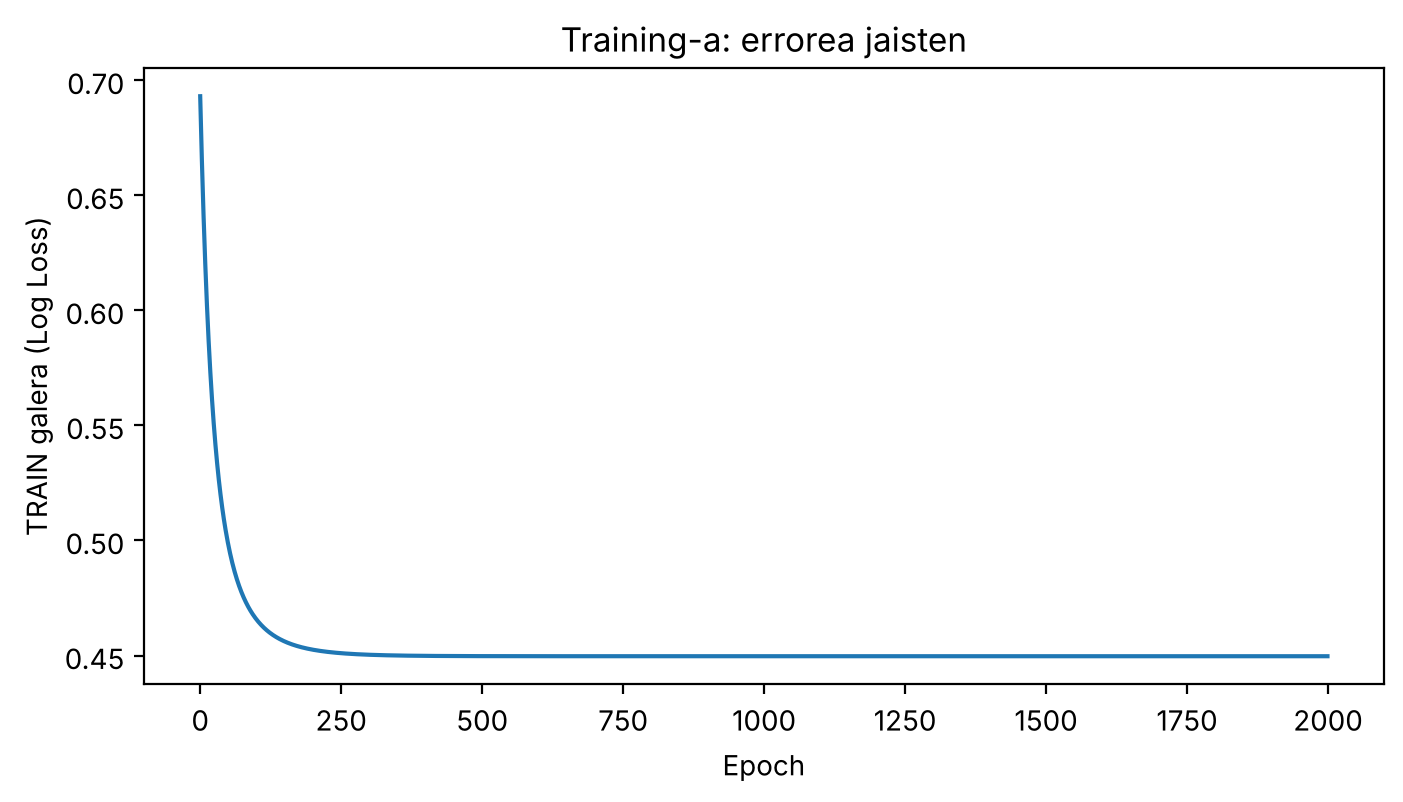

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(galerak)

plt.xlabel('Epoch')
plt.ylabel('TRAIN galera (Log Loss)')
plt.title('Training-a: errorea jaisten')

plt.show()


# C ATALA — Zer ikasi du neuronak? 🟢🟡


## C.1 — Interpretatu pisuak 🟡

Training-aren ondoren, neuronak `w` eta `b` ikasi ditu.

Galderak:

1. `distantzia_m`-ren pisua positiboa ala negatiboa da?
2. `zentrotik_angelua`-rena?
3. Pisu negatibo batek zer esan nahi du `z`-rentzat eta xG-rentzat?
4. Zein pisuk du magnitude handiagoa?

### Kontuz: ez alderatu zuzenean `-0.17` eta ikasitako pisua

Dataset-a sortzean:

```text
distantzia → metro gordinekin
angelua    → gradu gordinekin
```

erabili genituen.

Baina neuronak:

```text
distantzia eskalatua
angelua eskalatua
```

jasotzen ditu.

Horregatik ikasitako pisuak **beste eskala batean** daude.

> Espero duguna batez ere **zeinua eta erlazio orokorra** bat etortzea da, ez zenbaki bera zehazki.


In [13]:
print('Ikasitako w:', np.round(w, 3))
print('Ikasitako b:', round(b, 3))

print('\nPisu-mapaketa:')
print('  w[0] -> distantzia_m')
print('  w[1] -> zentrotik_angelua')


Ikasitako w: [-1.613 -0.684]
Ikasitako b: -0.904

Pisu-mapaketa:
  w[0] -> distantzia_m
  w[1] -> zentrotik_angelua


**C.1 Erantzunak:**

1. `distantzia_m`-ren pisua **negatiboa** da (−1.613): metro gehiago → z txikiagoa → xG txikiagoa.
2. `zentrotik_angelua`-rena ere **negatiboa** (−0.684): zentrotik alboago → xG txikiagoa.
3. Pisu negatibo batek esan nahi du feature hori handitzean **z jaisten** dela, eta sigmoidea monotonoa denez, **xG ere jaisten** dela. Bi zeinuak bat datoz datuak sortzeko erabili genituen −0.17 eta −0.035 koefizienteekin.
4. **Distantziarenak** du magnitude handiagoa (|−1.613| > |−0.684|). Feature-ak eskalatuta daudenez (1 desbideratze estandarreko aldaketa), magnitudeak konpara daitezke: distantzia da xG-n eragin handiena duen aldagaia.

## C.2 — TEST: orain bai, datu berriak 🟢

TEST datuak ez dira pisuak ikasteko erabili.

Lehenengo neuronak probabilitateak ematen ditu:

```text
p_test = [0.73, 0.31, 0.84, ...]
```

Gero sailkapena egiteko `0.5` atalasea erabiltzen dugu:

```text
0.73 ≥ 0.5 → True  → 1 (gola)
0.31 ≥ 0.5 → False → 0 (ez gola)
```

> **Atalasea ez dugu Log Loss training-ean erabiltzen.** Training-ak probabilitate osoekin egiten du lan.

Accuracy interpretatzeko, majority-class **baseline** bat ere kalkulatuko dugu:

> beti klase ohikoena iragarriko bagenu, zenbateko accuracy lortuko genuke?


In [14]:
# 1) Probabilitateak
p_test = aurreikusi(X_test_s, w, b)

# 2) Probabilitatea -> klasea
# True/False sortu eta gero 1/0 bihurtu
y_pred = (p_test >= 0.5).astype(int)

# 3) Accuracy
accuracy = (y_pred == y_test).mean()

# 4) Baseline:
# beti TEST-eko klase ohikoena iragarriko bagenu
gol_tasa_test = y_test.mean()
baseline = max(gol_tasa_test, 1 - gol_tasa_test)

print('Test accuracy :', round(accuracy, 3))
print('Baseline      :', round(baseline, 3))
print('Lehen 10 xG  :', np.round(p_test[:10], 3))
print('Lehen 10 klase:', y_pred[:10])


Test accuracy : 0.725
Baseline      : 0.633
Lehen 10 xG  : [0.018 0.62  0.235 0.3   0.403 0.842 0.698 0.057 0.863 0.1  ]
Lehen 10 klase: [0 1 0 0 0 1 1 0 1 0]


## C.3 — Jaurtiketa zehatzen xG-a 🟢

Orain guk asmatutako jaurtiketa berriei xG kalkulatuko diegu.

Garrantzitsua:

```python
scaler.transform(jaurtiketak)
```

erabiltzen dugu, **ez** `fit_transform()`.

Zergatik?

> Neuronak TRAIN-en ikasitako koordenatu-sistema berean jaso behar ditu jaurtiketa berriak.

Eta gogoratu: lehen neuronak ez du `gorputz_atala` ikusten.  
Beraz distantzia eta angelu bera duten oinezko eta buruzko bi jaurtiketei **xG bera** emango die.


In [15]:
# Zutabeen ordena:
# [distantzia_m, zentrotik_angelua]
jaurtiketak = np.array([
    [6, 2],
    [11, 0],
    [18, 15],
    [30, 45]
])

# EZ fit_transform():
# TRAIN-ek ikasitako scaler bera aplikatu bakarrik.
jaurtiketak_s = scaler.transform(jaurtiketak)

# Neuronaren xG probabilitateak
xg = aurreikusi(jaurtiketak_s, w, b)

for (d, a), p in zip(jaurtiketak, xg):
    print(f'{d:>2} m / {a:>2}° zentrotik -> xG = {p:.2f}')


 6 m /  2° zentrotik -> xG = 0.93
11 m /  0° zentrotik -> xG = 0.84
18 m / 15° zentrotik -> xG = 0.40
30 m / 45° zentrotik -> xG = 0.02


## C.4 — Zure neurona vs Scikit-learn 🟢

Orain gure inplementazioa Scikit-learn-ekin alderatuko dugu.

Hiztegia:

```text
gure w  ↔ lr.coef_
gure b  ↔ lr.intercept_
```

Bi ereduek Logistic Regression arazo bera modelatzen dute, baina pisuak ez dira zertan berdin-berdinak izan:

- gure eredua → **full-batch Gradient Descent** sinplea;
- Scikit-learn → optimizatzaile sofistikatuagoa erabiltzen du normalean;
- Scikit-learn → erregularizazioa erabiltzen du lehenespenez.

Beraz espero duguna:

> **portaera, probabilitate eta accuracy antzekoak**, baina ez derrigor pisu identikoak.


In [16]:
from sklearn.linear_model import LogisticRegression

# Scikit-learn eredua TRAIN datuekin entrenatu
lr = LogisticRegression(max_iter=5000)
lr.fit(X_train_s, y_train)

print(
    'ZURE neurona -> acc:',
    round(accuracy, 3),
    '| w:', np.round(w, 3),
    '| b:', round(b, 3)
)

print(
    'sklearn      -> acc:',
    round(lr.score(X_test_s, y_test), 3),
    '| coef_:', np.round(lr.coef_[0], 3),
    '| intercept_:', round(lr.intercept_[0], 3)
)


ZURE neurona -> acc: 0.725 | w: [-1.613 -0.684] | b: -0.904
sklearn      -> acc: 0.725 | coef_: [-1.574 -0.665] | intercept_: -0.89


# D ATALA — Lotura sare neuronalekin 🧠

Eraiki duguna:

```text
x1 ──w1──┐
         ├── Σ + b ── sigmoid ──> probabilitatea
x2 ──w2──┘
```

Logistic Regression-eko hiztegia eta neurona baten hiztegia ia bera dira:

| Logistic Regression | Neurona artifiziala |
|---|---|
| koefizienteak | weights / pisuak |
| intercept | bias |
| weighted sum | `z` |
| sigmoid | activation |
| probabilitatea | neuronaren output-a |

Beraz:

> **Erregresio logistiko binarioa = sigmoide-aktibazioko neurona bakar baten baliokidea.**

Hurrengo urratsa:

```text
neurona 1
neurona 2
neurona 3
    ↓
geruzak
    ↓
sare neuronala
```

Kontuz terminologiarekin: **perceptron klasikoak** normalean *step* aktibazioa eta beste ikaskuntza-arau bat erabiltzen ditu. Hemen **sigmoide-neurona** eraiki dugu.


# 🔴 ERRONKA GEHIGARRIA — gehitu `gorputz_atala`

Orain neuronari lehen ezkutatu diogun informazioa emango diogu:

```text
burua → 1
oina  → 0
```

Hirugarren input-a izango dugu:

$$
\hat{z}
=
b+w_1x_1+w_2x_2+w_3x_3
$$

non `x3 = buruz`.

### Python tresna berriak

Honelako zerbait beharko duzu:

```text
konparazioa
    ↓
True / False
    ↓ .astype(float)
1.0 / 0.0
```

`reshape(-1, 1)`-ek bektorea **zutabe** bihurtzen du, eta `np.hstack(...)`-ek zutabe berri hori `X`-ri eransten dio.

> Ariketa honetan `buruz` 0/1 bezala utziko dugu interpretazioa errazteko; ez da “debekatuta” dummy bat eskalatzea.

Helburua:

1. sortu `buruz` zutabe numerikoa TRAIN eta TEST-en;
2. gehitu hirugarren zutabe gisa;
3. entrenatu neurona berriro;
4. alderatu test accuracy;
5. interpretatu `w3`.

Galdera:

> **Zein zeinu espero duzu `buruz` pisuarentzat? Zergatik?**


In [17]:
# 1. buruz zutabe numerikoa: burua -> 1.0, oina -> 0.0, zutabe gisa (reshape(-1, 1))
buruz_train = (
    (train_df["gorputz_atala"] == "burua")
    .astype(float)
    .values
    .reshape(-1, 1)
)
buruz_test = (
    (test_df["gorputz_atala"] == "burua")
    .astype(float)
    .values
    .reshape(-1, 1)
)

# 2. Hirugarren zutabe gisa gehitu (np.hstack -> zutabeak horizontalki elkartu)
X_train_3 = np.hstack([X_train_s, buruz_train])
X_test_3 = np.hstack([X_test_s, buruz_test])

print("2 feature shape:", X_train_s.shape)
print("3 feature shape:", X_train_3.shape)

# 3. Neurona berria entrenatu (training loop bera)
w3 = np.zeros(X_train_3.shape[1])
b3 = 0.0
eta3 = 0.1
galerak3 = []

for epoch in range(2000):
    p3 = aurreikusi(X_train_3, w3, b3)
    galerak3.append(galera(y_train, p3))
    gw3, gb3 = gradientea(X_train_3, y_train, p3)
    w3 -= eta3 * gw3
    b3 -= eta3 * gb3

# 4. TEST accuracy alderatu
p3_test = aurreikusi(X_test_3, w3, b3)
y_pred3 = (p3_test >= 0.5).astype(int)
accuracy3 = (y_pred3 == y_test).mean()

print('2 feature TEST accuracy:', round(accuracy, 3))
print('3 feature TEST accuracy:', round(accuracy3, 3))
print('Azken TRAIN galera (2 vs 3):', round(float(galerak[-1]), 4), 'vs', round(float(galerak3[-1]), 4))

# 5. w3 interpretatu
print('Ikasitako w:', np.round(w3, 3), '-> [distantzia, angelua, buruz]')
print('Ikasitako b:', round(b3, 3))

2 feature shape: (480, 2)
3 feature shape: (480, 3)
2 feature TEST accuracy: 0.725
3 feature TEST accuracy: 0.725
Azken TRAIN galera (2 vs 3): 0.4497 vs 0.4493
Ikasitako w: [-1.619 -0.682 -0.174] -> [distantzia, angelua, buruz]
Ikasitako b: -0.867


**Erronkaren erantzuna:**

- **w3 (buruz) = −0.174 → negatiboa**, espero genuen bezala: datuak sortzean `−0.35 · buruz` erabili genuen, beraz buruzko jaurtiketek (beste guztia berdin) gol-probabilitate txikiagoa dute. Zeinua bat dator; magnitudea txikiagoa da laginaren zarata eta datu gutxi (480 jaurtiketa, ~%20 buruzkoak) direlako.
- **Test accuracy ez da aldatu** (0.725 → 0.725) eta train galera ia ez da jaitsi (0.4497 → 0.4493). `buruz`-en eragina txikia da distantziarekin alderatuta, eta 0.5 atalasearekin klase-iragarpen gehienak ez dira aldatzen. Hala ere, xG **probabilitateak** zehatzagoak dira orain: distantzia eta angelu bera duten oinezko eta buruzko jaurtiketek xG desberdina jasotzen dute.